# Simulated vs real mnt-correct trials

This notebook checks how realistic the output of [`simulate_mnt-correct_HRF.py`](simulate_mnt-correct_HRF.py) is. It compares the simulated mnt-correct trials with the real mnt-correct trials of the same subject, parcel and chromophore.

**Subject:** sub-723 &nbsp;·&nbsp; **Parcel:** `DorsAttnB_PostC_2_RH` (Schaefer/Yeo dorsal attention B, postcentral, right hemisphere) &nbsp;·&nbsp; **Chromophore:** HbO. Set by `subject`, `select_parcel` and `select_chromo` in section 1; the simulation injected HRFs into this parcel only.

| Group | Data | Trials |
|---|---|---|
| **Real mnt-correct** | original parcel series | `trial_type == 'mnt'` and `response_code == 0` in the original stim tables |
| **Simulated mnt-correct** | simulated series (original + injected HRFs) | the city-correct trials relabeled by the simulation (`is_sim`) |
| **City-correct** | simulated series | the remaining city-correct trials (reference) |
| **True HRF** | injected signal only | per-trial canonical HRF, locked to the labeled onset (includes jitter) |

All epochs are cut from the 0.02 Hz highpassed series (4th-order Butterworth, zero-phase, per run, the same filter as the Bayesian script) and baseline-corrected to −2–0 s.

Note that a simulated trial is a real **city** trial plus an injected HRF. It carries the city response and its noise. A real mnt-correct trial carries whatever the brain does on a correct withhold. The difference wave (mnt − city) is therefore the cleanest comparison between the two.

Sections:
1. Settings and data
2. Mean response with 95% CI, and the difference from city-correct
3. Single-trial images
4. Single-trial examples
5. Trial-level features (amplitude, noise, peak latency)
6. Per-run means
7. Context: real mnt − city amplitude across all parcels
8. Summary table

## 1. Settings and data

In [1]:
import os
import sys
import gzip
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from scipy.stats import t as t_dist

sim_code_dir = os.path.abspath('.')
sys.path.append(os.path.join(sim_code_dir, os.pardir))
sys.path.append(sim_code_dir)
from params_setting import *
from sim_utils import true_trial_hrfs

subject = 'sub-723'
select_parcel = 'DorsAttnB_PostC_2_RH'
select_chromo = 'HbO'
sim_name = 'sim_mnt-correct_10pct-city_canonical_A0.0158_cv0.25_slogsd0.15_jit3_seed0'
l_cutoff = 0.02            # highpass (Hz)
epoch_win = (-2.0, 18.0)   # s
amp_win = (3.0, 8.0)       # window (s) for the single-trial mean amplitude (around the canonical peak)
peak_win = (0.0, 15.0)     # window (s) to search the peak of a mean response
n_boot = 2000
seed = 1
rng = np.random.default_rng(seed)

# colors: reference categorical slots 1-3 in fixed order, truth in near-black
c_city, c_sim, c_real, c_true = '#2a78d6', '#eb6834', '#1baf7a', '#1f1f1f'

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.6})

In [2]:
# real inputs
stim_path, ts_path = get_image_space_paths(subject)
with gzip.open(stim_path, 'rb') as f:
    real_stims = pickle.load(f)['stims']
with open(ts_path, 'rb') as f:
    real_runs = pickle.load(f)['parcel_ts']

# simulated inputs and ground truth
sim_dir = os.path.join(project_path, 'derivatives', 'eeg', subject, 'simulation', sim_name)
with gzip.open(os.path.join(sim_dir, f'{subject}_sim_stims.pkl'), 'rb') as f:
    sim_stims = pickle.load(f)['stims']
with open(os.path.join(sim_dir, f'{subject}_sim_parcel_ts.pkl'), 'rb') as f:
    sim_runs = pickle.load(f)['parcel_ts']
with open(os.path.join(sim_dir, f'{subject}_sim_injected_uM.pkl'), 'rb') as f:
    injected = pickle.load(f)
truth = pd.read_csv(os.path.join(sim_dir, f'{subject}_sim_ground_truth.csv'))

assert len(real_runs) == len(sim_runs) == len(real_stims) == len(sim_stims)
n_runs = len(real_runs)
for r in range(n_runs):
    rs, ss = real_stims[r], sim_stims[r]
    print(f"run {r + 1}: real mnt-correct {((rs.trial_type == 'mnt') & (rs.response_code == 0)).sum():3d}, "
          f"simulated mnt-correct {ss.is_sim.sum():3d}, "
          f"city-correct (remaining) {((ss.trial_type == 'city') & (ss.response_code == 1)).sum():4d}")

run 1: real mnt-correct  38, simulated mnt-correct  41, city-correct (remaining)  368
run 2: real mnt-correct  38, simulated mnt-correct  41, city-correct (remaining)  369
run 3: real mnt-correct  48, simulated mnt-correct  40, city-correct (remaining)  362


In [3]:
def parcel_uM(run, parcel=select_parcel):
    return run.sel(parcel=parcel, chromo=select_chromo).pint.to('micromolar').pint.dequantify().values


def highpass(x, fs):
    sos = butter(4, l_cutoff, btype='highpass', fs=fs, output='sos')
    return sosfiltfilt(sos, x, axis=-1)


def epoch(x, t, onsets, fs, win=epoch_win):
    # epochs (trials, lags), baseline-corrected to the pre-onset samples; keep = trials fully inside the run
    lags = np.arange(int(round(win[0] * fs)), int(round(win[1] * fs)) + 1)
    idx = np.array([np.argmin(np.abs(t - o)) for o in onsets])[:, None] + lags[None, :]
    keep = (idx[:, 0] >= 0) & (idx[:, -1] < len(x))
    ep = x[idx[keep]]
    ep = ep - ep[:, lags < 0].mean(1, keepdims=True)
    return lags / fs, ep, keep


ep = {'real': [], 'sim': [], 'city': [], 'true': []}
ep_run = {'real': [], 'sim': [], 'true': []}
truth_kept = []
vtc = {'real': [], 'sim': []}
for r in range(n_runs):
    t = sim_runs[r].time.values
    fs = 1 / np.median(np.diff(t))
    x_real = highpass(parcel_uM(real_runs[r]), fs)
    x_sim = highpass(parcel_uM(sim_runs[r]), fs)
    rs, ss = real_stims[r], sim_stims[r]

    real_on = rs.loc[(rs.trial_type == 'mnt') & (rs.response_code == 0), 'onset'].values
    sim_on = ss.loc[ss.is_sim, 'onset'].values
    city_on = ss.loc[(ss.trial_type == 'city') & (ss.response_code == 1), 'onset'].values

    lag_t, e_real, keep_real = epoch(x_real, t, real_on, fs)
    _, e_sim, keep_sim = epoch(x_sim, t, sim_on, fs)
    vtc['real'].append(rs.loc[(rs.trial_type == 'mnt') & (rs.response_code == 0), 'VTC'].values[keep_real])
    vtc['sim'].append(ss.loc[ss.is_sim, 'VTC'].values[keep_sim])
    _, e_city, _ = epoch(x_sim, t, city_on, fs)

    tr = truth[truth.run_idx == r].sort_values('stim_idx')
    assert np.allclose(tr.onset.values, sim_on)
    tr = tr[keep_sim]
    e_true = true_trial_hrfs(tr, lag_t)
    truth_kept.append(tr)

    for k, e in [('real', e_real), ('sim', e_sim), ('city', e_city), ('true', e_true)]:
        ep[k].append(e)
    for k, e in [('real', e_real), ('sim', e_sim), ('true', e_true)]:
        ep_run[k].append(e)

ep = {k: np.concatenate(v) for k, v in ep.items()}
vtc = {k: np.concatenate(v) for k, v in vtc.items()}
truth_kept = pd.concat(truth_kept, ignore_index=True)
print({k: v.shape for k, v in ep.items()}, f'fs = {fs:.2f} Hz')

{'real': (124, 181), 'sim': (121, 181), 'city': (1098, 181), 'true': (121, 181)} fs = 8.99 Hz


In [4]:
def mean_ci(x, level=0.95):
    m = x.mean(0)
    h = t_dist.ppf(0.5 + level / 2, len(x) - 1) * x.std(0, ddof=1) / np.sqrt(len(x))
    return m, m - h, m + h


def ref_lines(ax):
    ax.axhline(0, color='#cccccc', lw=0.8, zorder=0)
    ax.axvline(0, color='#cccccc', lw=0.8, zorder=0)


labels = {'real': 'Real mnt-correct', 'sim': 'Simulated mnt-correct', 'city': 'City-correct',
          'true': 'True injected HRF'}
colors = {'real': c_real, 'sim': c_sim, 'city': c_city, 'true': c_true}
win_mask = lambda w: (lag_t >= w[0]) & (lag_t <= w[1])

## 2. Mean response with 95% CI

Left: the epoch mean of each group, with a t-based 95% CI across trials. Right: the difference from the city-correct mean (mnt − city). The city mean uses about 1,100 trials, so the CI of the difference is almost entirely the CI of the mnt trials, and that is what is shaded. The dashed line is the mean of the true injected HRFs, which is what the simulated difference wave should recover.

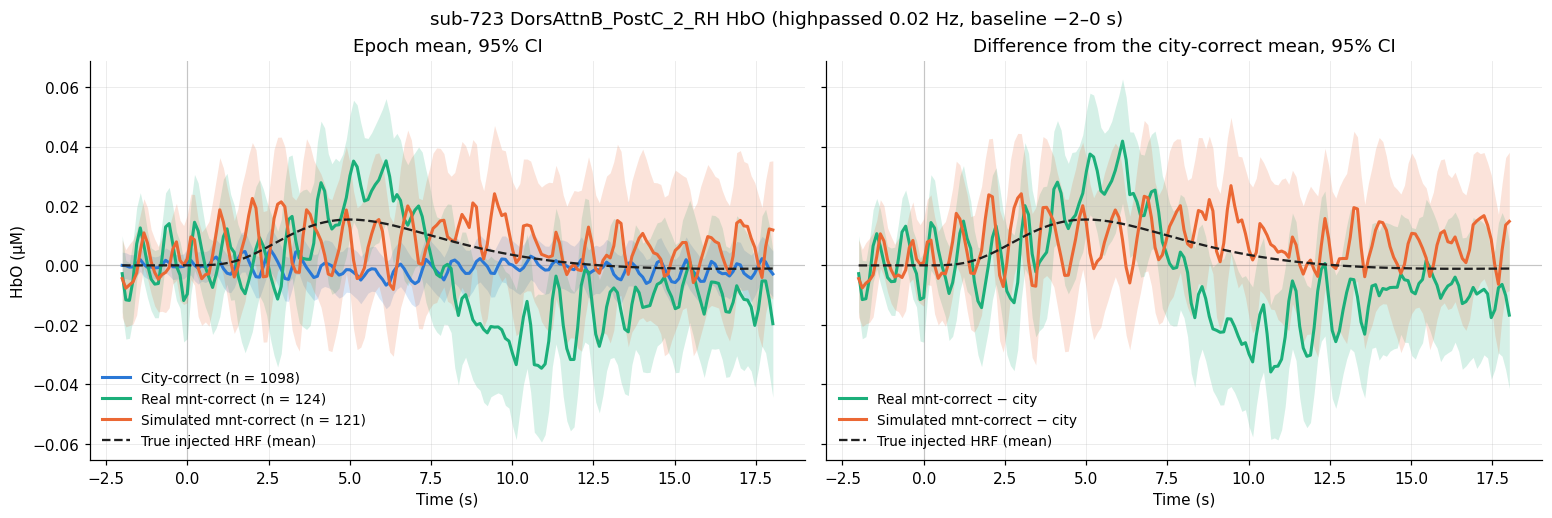

In [5]:
m_city = ep['city'].mean(0)
fig, axs = plt.subplots(1, 2, figsize=(14, 4.6), constrained_layout=True, sharey=True)
a = axs[0]
for k in ['city', 'real', 'sim']:
    m, lo, hi = mean_ci(ep[k])
    a.fill_between(lag_t, lo, hi, color=colors[k], alpha=0.18, lw=0)
    a.plot(lag_t, m, color=colors[k], lw=2, label=f'{labels[k]} (n = {len(ep[k])})')
a.plot(lag_t, ep['true'].mean(0), color=c_true, ls='--', lw=1.5, label=labels['true'] + ' (mean)')
a.set(xlabel='Time (s)', ylabel=f'{select_chromo} (µM)', title='Epoch mean, 95% CI')
a.legend(frameon=False, fontsize=9)
ref_lines(a)

b = axs[1]
for k in ['real', 'sim']:
    m, lo, hi = mean_ci(ep[k] - m_city)
    b.fill_between(lag_t, lo, hi, color=colors[k], alpha=0.18, lw=0)
    b.plot(lag_t, m, color=colors[k], lw=2, label=f'{labels[k]} − city')
b.plot(lag_t, ep['true'].mean(0), color=c_true, ls='--', lw=1.5, label=labels['true'] + ' (mean)')
b.set(xlabel='Time (s)', title='Difference from the city-correct mean, 95% CI')
b.legend(frameon=False, fontsize=9)
ref_lines(b)
fig.suptitle(f'{subject} {select_parcel} {select_chromo} (highpassed {l_cutoff} Hz, baseline −2–0 s)')
plt.show()

## 3. Single-trial images

Each row is one trial, sorted by its VTC (variance time course; low = in the zone, high = out of the zone). The narrow strip left of each image shows the VTC of each row. The real mnt-correct trials use the VTC of the mountain trial itself. The simulated trials use the VTC of the city trial that was relabeled, so for them VTC is not linked to the injected HRF, which was drawn independently of it. The data images share one color scale (diverging, centered at 0 µM). The right image shows the true injected HRFs of the simulated trials in the same order as the middle image.

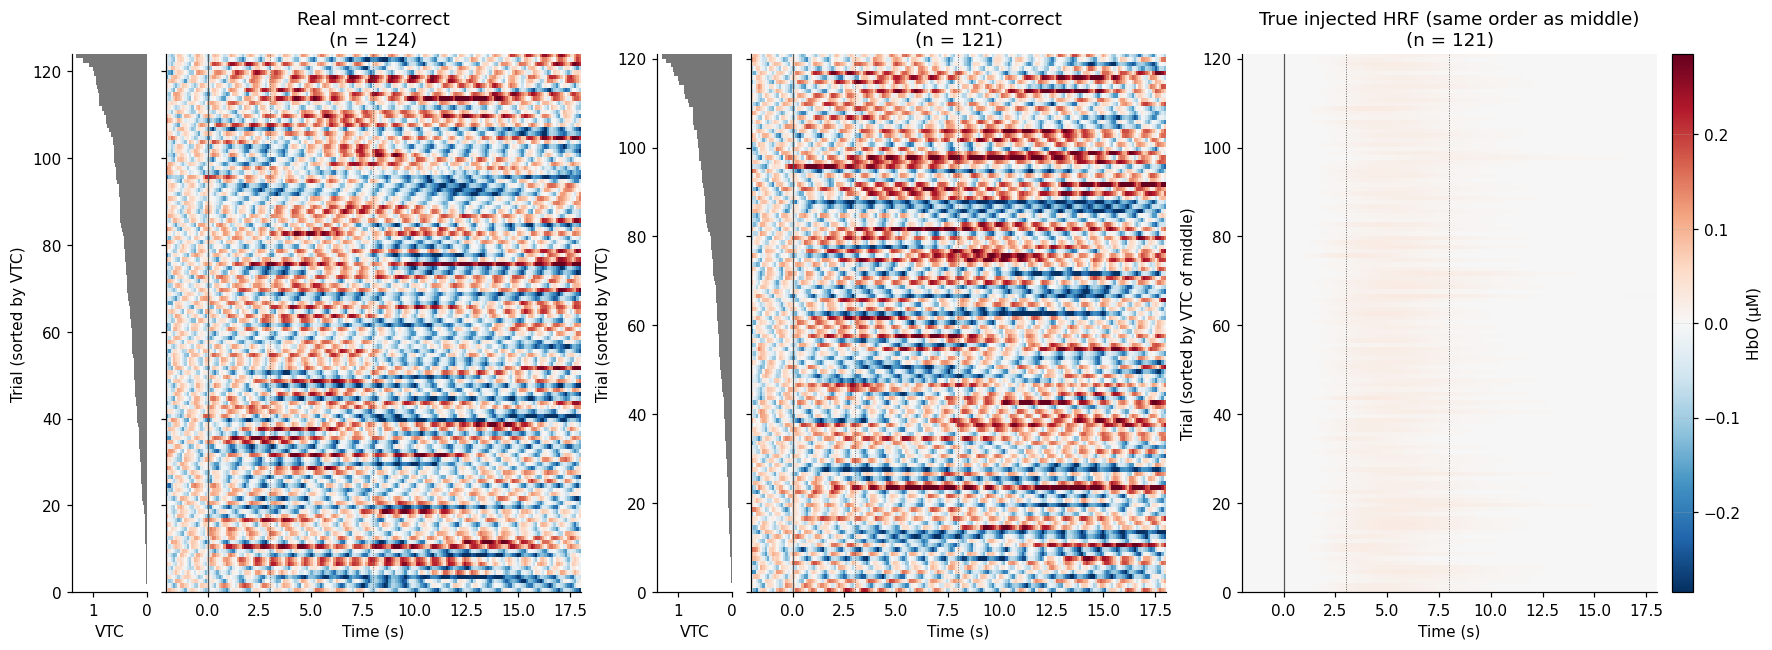

Real mnt-correct: Spearman r(VTC, mean amplitude 3-8 s) = +0.205 (n = 124)
Simulated mnt-correct: Spearman r(VTC, mean amplitude 3-8 s) = +0.290 (n = 121)


In [6]:
amp_mask = win_mask(amp_win)
vmax = np.percentile(np.abs(np.concatenate([ep['real'], ep['sim']])), 98)
order_real = np.argsort(vtc['real'], kind='stable')
order_sim = np.argsort(vtc['sim'], kind='stable')
vtc_max = max(vtc['real'].max(), vtc['sim'].max())

fig = plt.figure(figsize=(16, 5.8), constrained_layout=True)
gs = fig.add_gridspec(1, 6, width_ratios=[0.18, 1, 0.18, 1, 1, 0.05])
panels = [(gs[0], gs[1], ep['real'][order_real], vtc['real'][order_real], labels['real']),
          (gs[2], gs[3], ep['sim'][order_sim], vtc['sim'][order_sim], labels['sim']),
          (None, gs[4], ep['true'][order_sim], None, labels['true'] + ' (same order as middle)')]
for g_v, g_im, x, v, ttl in panels:
    a = fig.add_subplot(g_im)
    im = a.imshow(x, aspect='auto', cmap='RdBu_r', vmin=-vmax, vmax=vmax, origin='lower', interpolation='nearest',
                  extent=[lag_t[0], lag_t[-1], 0, len(x)])
    a.axvline(0, color='#555555', lw=0.8)
    for w in amp_win:
        a.axvline(w, color='#555555', lw=0.6, ls=':')
    a.set(xlabel='Time (s)', title=f'{ttl}\n(n = {len(x)})')
    a.grid(False)
    if v is not None:
        av = fig.add_subplot(g_v, sharey=a)
        av.barh(np.arange(len(v)) + 0.5, v, height=1.0, color='#777777', lw=0)
        av.set(xlim=(vtc_max * 1.05, 0), xlabel='VTC', ylabel='Trial (sorted by VTC)')
        av.grid(False)
        a.tick_params(labelleft=False)
    else:
        a.set_ylabel('Trial (sorted by VTC of middle)')
fig.colorbar(im, cax=fig.add_subplot(gs[5]), label=f'{select_chromo} (µM)')
plt.show()

# does the 3-8 s amplitude change with VTC?
for k in ['real', 'sim']:
    r_s = pd.Series(ep[k][:, amp_mask].mean(1)).corr(pd.Series(vtc[k]), method='spearman')
    print(f"{labels[k]}: Spearman r(VTC, mean amplitude {amp_win[0]:.0f}-{amp_win[1]:.0f} s) = {r_s:+.3f} (n = {len(vtc[k])})")

## 4. Single-trial examples

Six random trials from each group, on a shared y axis. The simulated trials show their true injected HRF (dashed).

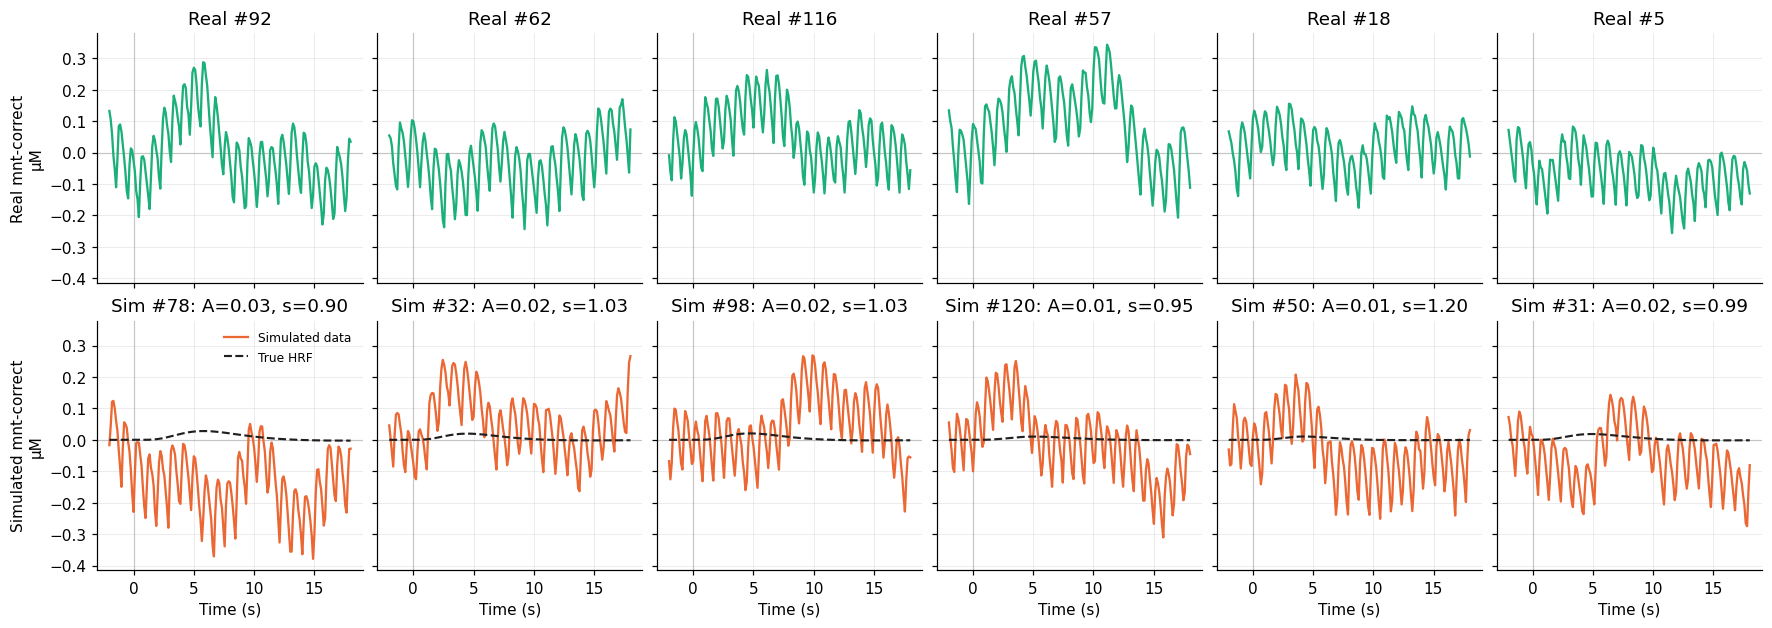

In [7]:
n_ex = 6
ex_real = rng.choice(len(ep['real']), n_ex, replace=False)
ex_sim = rng.choice(len(ep['sim']), n_ex, replace=False)
fig, axs = plt.subplots(2, n_ex, figsize=(16, 5.6), constrained_layout=True, sharex=True, sharey=True)
for k in range(n_ex):
    a = axs[0, k]
    a.plot(lag_t, ep['real'][ex_real[k]], color=c_real, lw=1.5)
    a.set(title=f'Real #{ex_real[k] + 1}')
    ref_lines(a)
    b = axs[1, k]
    i = ex_sim[k]
    b.plot(lag_t, ep['sim'][i], color=c_sim, lw=1.5, label='Simulated data')
    b.plot(lag_t, ep['true'][i], color=c_true, ls='--', lw=1.4, label='True HRF')
    row = truth_kept.iloc[i]
    b.set(title=f'Sim #{i + 1}: A={row.amp_uM:.2f}, s={row.time_scale:.2f}', xlabel='Time (s)')
    ref_lines(b)
axs[0, 0].set_ylabel('Real mnt-correct\nµM')
axs[1, 0].set_ylabel('Simulated mnt-correct\nµM')
axs[1, 0].legend(frameon=False, fontsize=8)
plt.show()

## 5. Trial-level features

* **Mean amplitude 3–8 s** of each trial (baseline-corrected). The injected HRF shifts the simulated distribution right of city-correct by about the mean of the true HRF in this window.
* **Single-trial SD** over the whole epoch, a measure of how noisy a trial is. Real and simulated mnt trials come from the same recording, so they should match closely.
* **Peak amplitude and latency of the mean response**, bootstrapped over trials (2,000 resamples, peak searched in 0–15 s). This shows how well each group's mean shape is determined with its trial count, and where the true values sit.

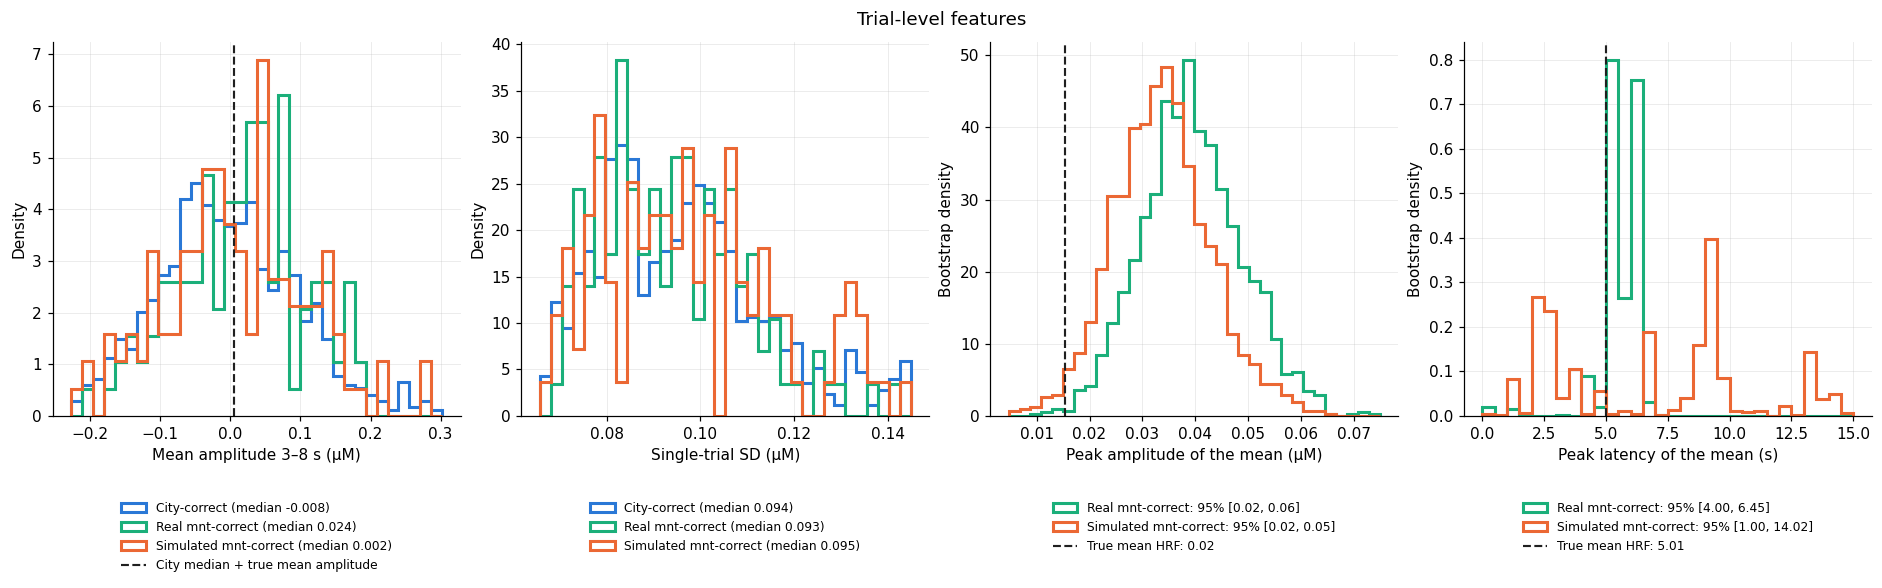

In [8]:
feat = {k: pd.DataFrame({'amp_3_8': ep[k][:, amp_mask].mean(1), 'sd': ep[k].std(1)}) for k in ['city', 'real', 'sim']}
true_amp_3_8 = ep['true'][:, amp_mask].mean(1)

pk_mask = win_mask(peak_win)
def boot_peak(x):
    out = np.empty((n_boot, 2))
    for b in range(n_boot):
        m = x[rng.integers(0, len(x), len(x))].mean(0)[pk_mask]
        out[b] = m.max(), lag_t[pk_mask][m.argmax()]
    return out
boot = {k: boot_peak(ep[k]) for k in ['real', 'sim']}
m_true = ep['true'].mean(0)[pk_mask]
true_peak = (m_true.max(), lag_t[pk_mask][m_true.argmax()])

fig, axs = plt.subplots(1, 4, figsize=(17, 5.2), constrained_layout=True)
leg = dict(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2))
for a, col, xl in [(axs[0], 'amp_3_8', f'Mean amplitude {amp_win[0]:.0f}–{amp_win[1]:.0f} s (µM)'),
                   (axs[1], 'sd', 'Single-trial SD (µM)')]:
    allv = np.concatenate([feat[k][col] for k in feat])
    bins = np.linspace(*np.percentile(allv, [0.5, 99.5]), 35)
    for k in ['city', 'real', 'sim']:
        a.hist(feat[k][col], bins=bins, density=True, histtype='step', lw=2, color=colors[k],
               label=f'{labels[k]} (median {np.median(feat[k][col]):.3f})')
    if col == 'amp_3_8':
        a.axvline(np.median(feat['city'].amp_3_8) + true_amp_3_8.mean(), color=c_true, ls='--', lw=1.4,
                  label='City median + true mean amplitude')
    a.set(xlabel=xl, ylabel='Density')
    a.legend(**leg)

for j, (a, xl) in enumerate([(axs[2], 'Peak amplitude of the mean (µM)'), (axs[3], 'Peak latency of the mean (s)')]):
    allv = np.concatenate([boot[k][:, j] for k in boot])
    bins = np.linspace(allv.min(), allv.max(), 35) if j == 0 else np.arange(peak_win[0], peak_win[1] + 0.5, 0.5)
    for k in ['real', 'sim']:
        lo, hi = np.percentile(boot[k][:, j], [2.5, 97.5])
        a.hist(boot[k][:, j], bins=bins, density=True, histtype='step', lw=2, color=colors[k],
               label=f'{labels[k]}: 95% [{lo:.2f}, {hi:.2f}]')
    a.axvline(true_peak[j], color=c_true, ls='--', lw=1.4, label=f'True mean HRF: {true_peak[j]:.2f}')
    a.set(xlabel=xl, ylabel='Bootstrap density')
    a.legend(**leg)
fig.suptitle('Trial-level features')
plt.show()

## 6. Per-run means

The same comparison as section 2, split by run. A response that appears in only one run would show up here.

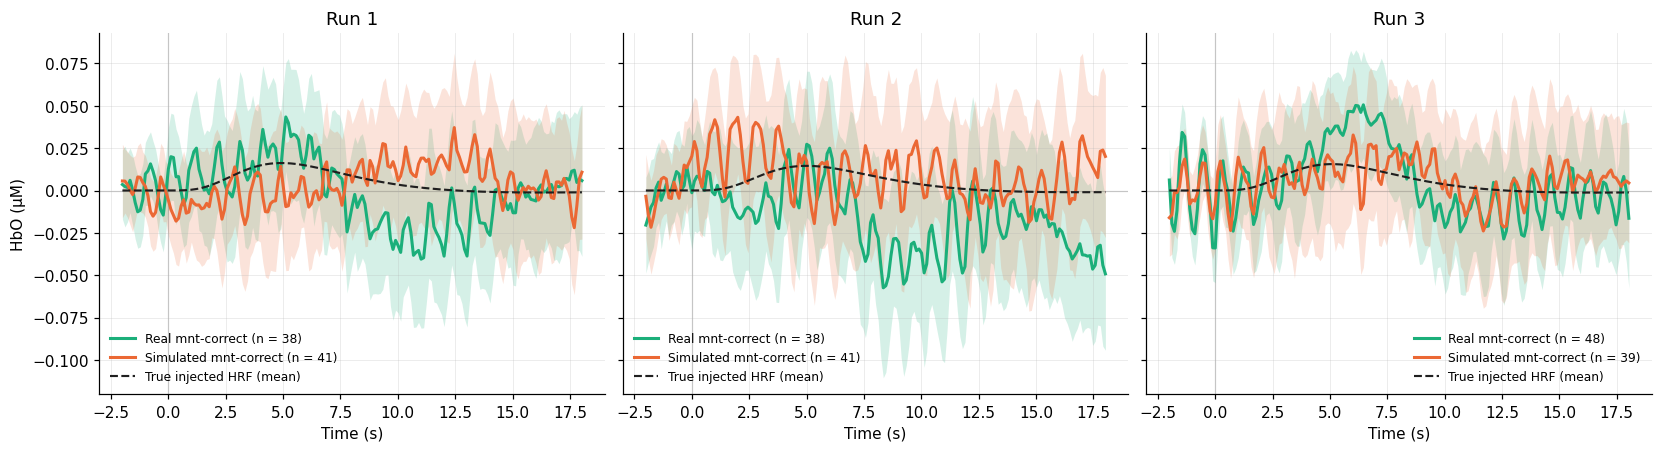

In [9]:
fig, axs = plt.subplots(1, n_runs, figsize=(5 * n_runs, 4), constrained_layout=True, sharey=True)
axs = np.atleast_1d(axs)
for r, a in enumerate(axs):
    for k in ['real', 'sim']:
        m, lo, hi = mean_ci(ep_run[k][r])
        a.fill_between(lag_t, lo, hi, color=colors[k], alpha=0.18, lw=0)
        a.plot(lag_t, m, color=colors[k], lw=2, label=f'{labels[k]} (n = {len(ep_run[k][r])})')
    a.plot(lag_t, ep_run['true'][r].mean(0), color=c_true, ls='--', lw=1.4, label=labels['true'] + ' (mean)')
    a.set(title=f'Run {r + 1}', xlabel='Time (s)')
    a.legend(frameon=False, fontsize=8)
    ref_lines(a)
axs[0].set_ylabel(f'{select_chromo} (µM)')
plt.show()

## 7. Context: real mnt − city amplitude across all parcels

The simulated amplitude (A ~ 0.2 µM) is an assumption. To see whether it is realistic for this subject, this section computes, for every parcel, the real (mnt-correct − city-correct) mean in the 3–8 s window, using the original data. The selected parcel and the same statistic for the injected HRF are marked.

Averaging is linear, so the epoch mean is computed lag by lag across all parcels at once, and the baseline is removed from the mean.

395 / 603 parcels with signal (the rest are insensitive, SD ~ 0)


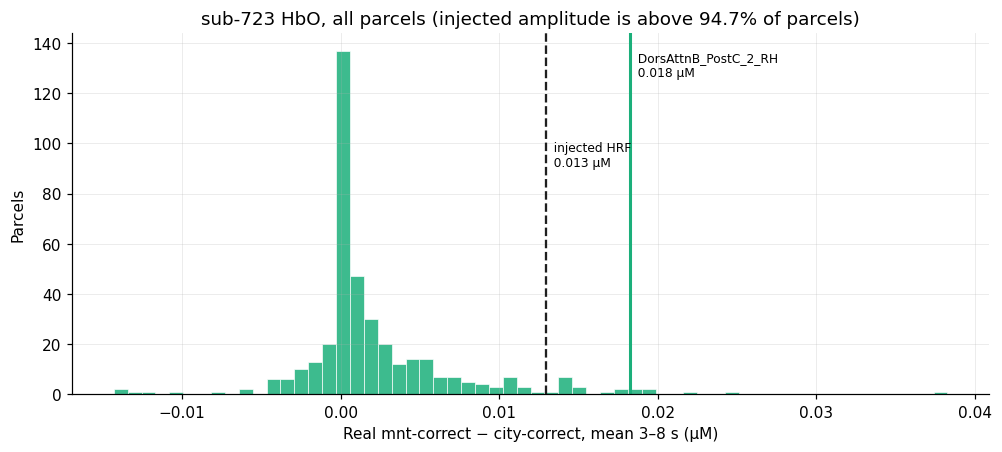

Largest real mnt − city amplitudes (µM):
VisCent_ExStr_13_RH      0.038
SomMotB_Cent_3_RH        0.025
VisCent_ExStr_14_LH      0.022
VisCent_ExStr_7_LH       0.020
SomMotA_4_RH             0.019
SalVentAttnB_IPL_2_RH    0.019
DorsAttnB_PostC_2_RH     0.018
VisCent_ExStr_10_RH      0.018
SalVentAttnB_IPL_1_RH    0.018
DorsAttnA_ParOcc_3_RH    0.017


In [10]:
def mean_epoch_all_parcels(X, t, onsets, fs):
    # X: (parcel, time). Returns the baseline-corrected mean epoch (parcel, lag).
    lags = np.arange(int(round(epoch_win[0] * fs)), int(round(epoch_win[1] * fs)) + 1)
    idx = np.array([np.argmin(np.abs(t - o)) for o in onsets])[:, None] + lags[None, :]
    idx = idx[(idx[:, 0] >= 0) & (idx[:, -1] < X.shape[1])]
    m = np.stack([X[:, idx[:, l]].sum(1) for l in range(len(lags))], 1)
    return m, len(idx), lags

sum_d = {'mnt': 0, 'city': 0}
n_d = {'mnt': 0, 'city': 0}
for r in range(n_runs):
    run = real_runs[r].sel(chromo=select_chromo).pint.to('micromolar').pint.dequantify()
    parcels = run.parcel.values
    t = run.time.values
    fs = 1 / np.median(np.diff(t))
    X = highpass(run.transpose('parcel', 'time').values, fs)
    rs = real_stims[r]
    for k, sel in [('mnt', (rs.trial_type == 'mnt') & (rs.response_code == 0)),
                   ('city', (rs.trial_type == 'city') & (rs.response_code == 1))]:
        s_, n_, lags = mean_epoch_all_parcels(X, t, rs.loc[sel, 'onset'].values, fs)
        sum_d[k] = sum_d[k] + s_
        n_d[k] += n_
mean_d = {k: sum_d[k] / n_d[k] for k in sum_d}
mean_d = {k: v - v[:, lags < 0].mean(1, keepdims=True) for k, v in mean_d.items()}
diff_amp = (mean_d['mnt'] - mean_d['city'])[:, amp_mask].mean(1)
# insensitive parcels carry (near) zero signal; keep parcels whose highpassed series has a non-trivial SD
run_sd = np.nanstd(highpass(real_runs[0].sel(chromo=select_chromo).pint.to('micromolar').pint.dequantify()
                            .transpose('parcel', 'time').values, fs), axis=1)
ok = np.isfinite(diff_amp) & (run_sd > 1e-3 * np.nanmax(run_sd))
p_i = list(parcels).index(select_parcel)
print(f'{ok.sum()} / {len(parcels)} parcels with signal (the rest are insensitive, SD ~ 0)')

fig, a = plt.subplots(figsize=(9, 4), constrained_layout=True)
a.hist(diff_amp[ok], bins=60, color=c_real, alpha=0.85, edgecolor='white', lw=0.5)
a.axvline(diff_amp[p_i], color=c_real, lw=2, ls='-')
a.text(diff_amp[p_i], a.get_ylim()[1] * 0.95, f'  {select_parcel}\n  {diff_amp[p_i]:.3f} µM', va='top', fontsize=8)
a.axvline(true_amp_3_8.mean(), color=c_true, lw=1.5, ls='--')
a.text(true_amp_3_8.mean(), a.get_ylim()[1] * 0.70, f'  injected HRF\n  {true_amp_3_8.mean():.3f} µM', va='top', fontsize=8)
pct = (diff_amp[ok] < true_amp_3_8.mean()).mean() * 100
a.set(xlabel=f'Real mnt-correct − city-correct, mean {amp_win[0]:.0f}–{amp_win[1]:.0f} s (µM)', ylabel='Parcels',
      title=f'{subject} {select_chromo}, all parcels (injected amplitude is above {pct:.1f}% of parcels)')
plt.show()

top = pd.Series(diff_amp[ok], index=parcels[ok]).sort_values(ascending=False)
print('Largest real mnt − city amplitudes (µM):')
print(top.head(10).round(3).to_string())

## 8. Summary table

In [11]:
def peak_of_mean(x):
    m = x.mean(0)[pk_mask]
    return m.max(), lag_t[pk_mask][m.argmax()]

rows = []
for k in ['city', 'real', 'sim', 'true']:
    x = ep[k]
    pa, pl = peak_of_mean(x)
    d = x - m_city if k in ('real', 'sim') else None
    dpa, dpl = peak_of_mean(d) if d is not None else (np.nan, np.nan)
    rows.append({'group': labels[k], 'n trials': len(x),
                 'peak of mean (µM)': pa, 'peak latency (s)': pl,
                 'mean 3–8 s (µM)': x[:, amp_mask].mean(),
                 'peak of (mean − city) (µM)': dpa if k != 'true' else pa,
                 'latency of (mean − city) (s)': dpl if k != 'true' else pl,
                 'median single-trial SD (µM)': np.median(x.std(1)) if k != 'true' else np.nan})
summary = pd.DataFrame(rows).set_index('group')
summary.round(3)

,n trials,peak of mean (µM),peak latency (s),mean 3–8 s (µM),peak of (mean − city) (µM),latency of (mean − city) (s),median single-trial SD (µM)
group,,,,,,,
City-correct,1098,0.005,2.559,-0.002,NaN,NaN,0.094
Real mnt-correct,124,0.035,6.119,0.017,0.042,6.119,0.093
Simulated mnt-correct,121,0.024,9.456,0.007,0.027,9.456,0.095
True injected HRF,121,0.015,5.006,0.013,0.015,5.006,NaN


## 9. Observations

Numbers below are from the run of 2026-11-23 (sub-723, `DorsAttnB_PostC_2_RH`, HbO, seed 0). The simulation now uses `amp_mean = 'match_real'`: A is fit to the real (mnt-correct − city-correct) epoch mean, giving A = 0.0158 µM (the earlier version used A = 0.2 µM).

1. **The simulated and real responses now have similar sizes.** In the 3–8 s window the true injected HRF averages 0.013 µM, and the real mnt − city difference 0.019 µM. The injected value is a little lower, because the least-squares fit over 0–18 s is pulled down by the real response's negative dip at about 9–12 s, which a canonical HRF does not have.
2. **At this amplitude the response is near the noise floor.** The 95% CIs of both the real and the simulated difference waves include 0 at most lags. In the per-trial images the injected HRF can't be seen by eye.
3. **The peak of a noisy mean overestimates the amplitude.** The bootstrapped peak of the simulated mean is 0.02–0.05 µM (95%), while the true peak is 0.015 µM. The real mnt-correct peak (0.02–0.06 µM) is inflated in the same way, which is why the fitted A (0.016 µM) is lower than the real peak in section 2.
4. **The peak latency of the simulated mean can't be pinned down** (95% interval 1.0–14.0 s, truth 5.0 s). The real response's latency is better determined (4.0–6.5 s), so the real response has a clearer shape than its fitted amplitude alone suggests.
5. **Noise is now matched.** Median single-trial SD is 0.094 (city-correct), 0.093 (real mnt-correct) and 0.095 µM (simulated mnt-correct). With A = 0.2 µM the city SD looked higher (0.126 µM). That was because city epochs overlapped the large injected HRFs; it was not a real difference between trial types.
6. **VTC (section 3).** Neither group shows a visible VTC pattern. The Spearman correlations between VTC and 3–8 s amplitude are +0.21 (real) and +0.29 (simulated). The simulated HRFs were drawn without regard to VTC, so a correlation of that size can come from the underlying data alone. The real-trial correlation is not evidence of a VTC effect by itself.
7. **Context (section 7).** The real mnt − city amplitude in this parcel (0.018 µM, 3–8 s mean) is among the largest of the 395 parcels with signal (maximum 0.038 µM). So this parcel is a good-case test of recovery at a realistic SNR.
